# Soil inputs across crops

Checks that `simplace/<crop>/data/soil/soil.csv` (and `data/soilcnp/*.xml`) are identical for all six crops, then maps and summarises the soil variables.

Note: soil.csv is known to be wrong south of ~52.25°N (silt-loam where BZE measures sand) — see the N–S step in the maps below.


In [1]:
import hashlib, os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path(os.environ.get('BRANDENBURG_SCENARIOS_ROOT', Path.cwd().resolve().parents[1]))
CROPS = ['winter_wheat','winter_rapeseed','spring_barley','potato','maize','sugar_beet']
md5 = lambda p: hashlib.md5(p.read_bytes()).hexdigest()

## 1. Identical across crops? (byte level)


In [2]:
rows=[]
for c in CROPS:
    d = ROOT/'simplace'/c/'data'
    for f in [d/'soil'/'soil.csv', *sorted((d/'soilcnp').glob('*.xml'))]:
        rows.append(dict(crop=c, file=str(f.relative_to(d)), md5=md5(f)))
h = pd.DataFrame(rows).pivot(index='file', columns='crop', values='md5')[CROPS]
h['identical'] = h.nunique(axis=1)==1
h

crop,winter_wheat,winter_rapeseed,spring_barley,potato,maize,sugar_beet,identical
file,,,,,,,
soil/soil.csv,132e4fbb73883d957304642e7f4c576f,132e4fbb73883d957304642e7f4c576f,132e4fbb73883d957304642e7f4c576f,132e4fbb73883d957304642e7f4c576f,132e4fbb73883d957304642e7f4c576f,132e4fbb73883d957304642e7f4c576f,True
soilcnp/Auxiliary_Changed.xml,fd05577d999c6cdb37ebf1851e5fab1c,fd05577d999c6cdb37ebf1851e5fab1c,fd05577d999c6cdb37ebf1851e5fab1c,fd05577d999c6cdb37ebf1851e5fab1c,fd05577d999c6cdb37ebf1851e5fab1c,fd05577d999c6cdb37ebf1851e5fab1c,True
soilcnp/Carbon_Changed.xml,46f80bbbec0b7590b10647651aa8f2e4,46f80bbbec0b7590b10647651aa8f2e4,46f80bbbec0b7590b10647651aa8f2e4,46f80bbbec0b7590b10647651aa8f2e4,46f80bbbec0b7590b10647651aa8f2e4,46f80bbbec0b7590b10647651aa8f2e4,True
soilcnp/Crop_Changed.xml,b3786961b815bfd9dcc7a385ac758328,b3786961b815bfd9dcc7a385ac758328,b3786961b815bfd9dcc7a385ac758328,b3786961b815bfd9dcc7a385ac758328,b3786961b815bfd9dcc7a385ac758328,b3786961b815bfd9dcc7a385ac758328,True
soilcnp/Init2010_Changed.xml,5dd5027bbc868c5c6a9a843c3e0e03be,5dd5027bbc868c5c6a9a843c3e0e03be,5dd5027bbc868c5c6a9a843c3e0e03be,5dd5027bbc868c5c6a9a843c3e0e03be,5dd5027bbc868c5c6a9a843c3e0e03be,5dd5027bbc868c5c6a9a843c3e0e03be,True
soilcnp/InitP_Changed.xml,ee1b07bdde72e6b1ddfe306ae5139133,ee1b07bdde72e6b1ddfe306ae5139133,ee1b07bdde72e6b1ddfe306ae5139133,ee1b07bdde72e6b1ddfe306ae5139133,ee1b07bdde72e6b1ddfe306ae5139133,ee1b07bdde72e6b1ddfe306ae5139133,True
soilcnp/Nitrogen_Changed.xml,16ee38dc980496b8440c758a56947003,16ee38dc980496b8440c758a56947003,16ee38dc980496b8440c758a56947003,16ee38dc980496b8440c758a56947003,16ee38dc980496b8440c758a56947003,16ee38dc980496b8440c758a56947003,True
soilcnp/Phosphorus_Changed.xml,6c82d233b62dc3fbb541fe6fbc369280,6c82d233b62dc3fbb541fe6fbc369280,6c82d233b62dc3fbb541fe6fbc369280,6c82d233b62dc3fbb541fe6fbc369280,6c82d233b62dc3fbb541fe6fbc369280,6c82d233b62dc3fbb541fe6fbc369280,True


## 2. Identical across crops? (value level)


In [3]:
soils = {c: pd.read_csv(ROOT/'simplace'/c/'data'/'soil'/'soil.csv') for c in CROPS}
ref = soils[CROPS[0]]
for c in CROPS[1:]:
    print(f'{c:16s} same shape: {soils[c].shape==ref.shape}  equal values: {soils[c].equals(ref)}')
soil = ref.copy(); print(soil.shape)

winter_rapeseed  same shape: True  equal values: True
spring_barley    same shape: True  equal values: True
potato           same shape: True  equal values: True
maize            same shape: True  equal values: True
sugar_beet       same shape: True  equal values: True
(15066, 142)


## 3. Join to site coordinates


In [4]:
sites = pd.read_csv(ROOT/'simplace'/'winter_wheat'/'project'/'sites_winter_wheat.csv')
soil['location'] = soil['location'].astype(str); sites['vLocationID'] = sites['vLocationID'].astype(str)
df = soil.merge(sites[['vLocationID','vlat','vlon','vNUTSID']], left_on='location', right_on='vLocationID', how='left')
print('sites without coords:', df['vlat'].isna().sum())
# derived
df['silt_1'] = 100 - df['sand_1'] - df['clay_1']
depth = df[[f'depth_{i}' for i in range(1,7)]].values  # layer thickness or bottom depth, see table below
df.filter(like='depth').describe().T

sites without coords: 0


,count,mean,std,min,25%,50%,75%,max
dampingdepth,15066.0,6.0,0.000000e+00,6.0,6.0,6.0,6.0,6.0
depth_1,15066.0,0.1,1.387825e-17,0.1,0.1,0.1,0.1,0.1
depth_2,15066.0,0.3,5.551299e-17,0.3,0.3,0.3,0.3,0.3
depth_3,15066.0,0.5,0.000000e+00,0.5,0.5,0.5,0.5,0.5
depth_4,15066.0,0.7,1.110260e-16,0.7,0.7,0.7,0.7,0.7
depth_5,15066.0,1.0,0.000000e+00,1.0,1.0,1.0,1.0,1.0
depth_6,15066.0,2.0,0.000000e+00,2.0,2.0,2.0,2.0,2.0


Derived: plant-available water capacity per layer = (fc − wp) × layer thickness. Thickness taken from `SoilLayerDepth_*` if cumulative.


In [5]:
L = df[[f'SoilLayerDepth_{i}' for i in range(1,7)]].values
thick = np.diff(np.c_[np.zeros(len(L)), L], axis=1) if np.all(np.diff(L,axis=1)>=0) else L
fc = df[[f'soilwater_fc_{i}' for i in range(1,7)]].values; wp = df[[f'soilwater_wp_{i}' for i in range(1,7)]].values
df['PAWC_mm'] = ((fc-wp)*thick*1000).sum(axis=1)
df['PAWC_mm'].describe()

count    15066.000000
mean       143.738809
std         57.598177
min         44.277359
25%         84.946817
50%        145.949206
75%        197.744283
max        307.381501
Name: PAWC_mm, dtype: float64

## 4. Summary of every numeric variable


In [6]:
num = df.select_dtypes('number').drop(columns=['vlat','vlon'])
pd.set_option('display.max_rows', 200)
num.describe().T[['mean','std','min','50%','max']]

,mean,std,min,50%,max
dampingdepth,6.000000,0.000000e+00,6.000000,6.000000,6.000000
soilwater_fc_global,0.123205,7.668270e-02,0.033350,0.102480,0.428806
soilwater_sat_global,0.358991,2.507356e-02,0.317688,0.354729,0.501364
drainage_rate,50.000000,0.000000e+00,50.000000,50.000000,50.000000
deltatheta,0.010000,1.734781e-18,0.010000,0.010000,0.010000
DZF,0.100000,1.387825e-17,0.100000,0.100000,0.100000
depth_1,0.100000,1.387825e-17,0.100000,0.100000,0.100000
depth_2,0.300000,5.551299e-17,0.300000,0.300000,0.300000
depth_3,0.500000,0.000000e+00,0.500000,0.500000,0.500000
depth_4,0.700000,1.110260e-16,0.700000,0.700000,0.700000


## 5. Maps — topsoil and profile variables


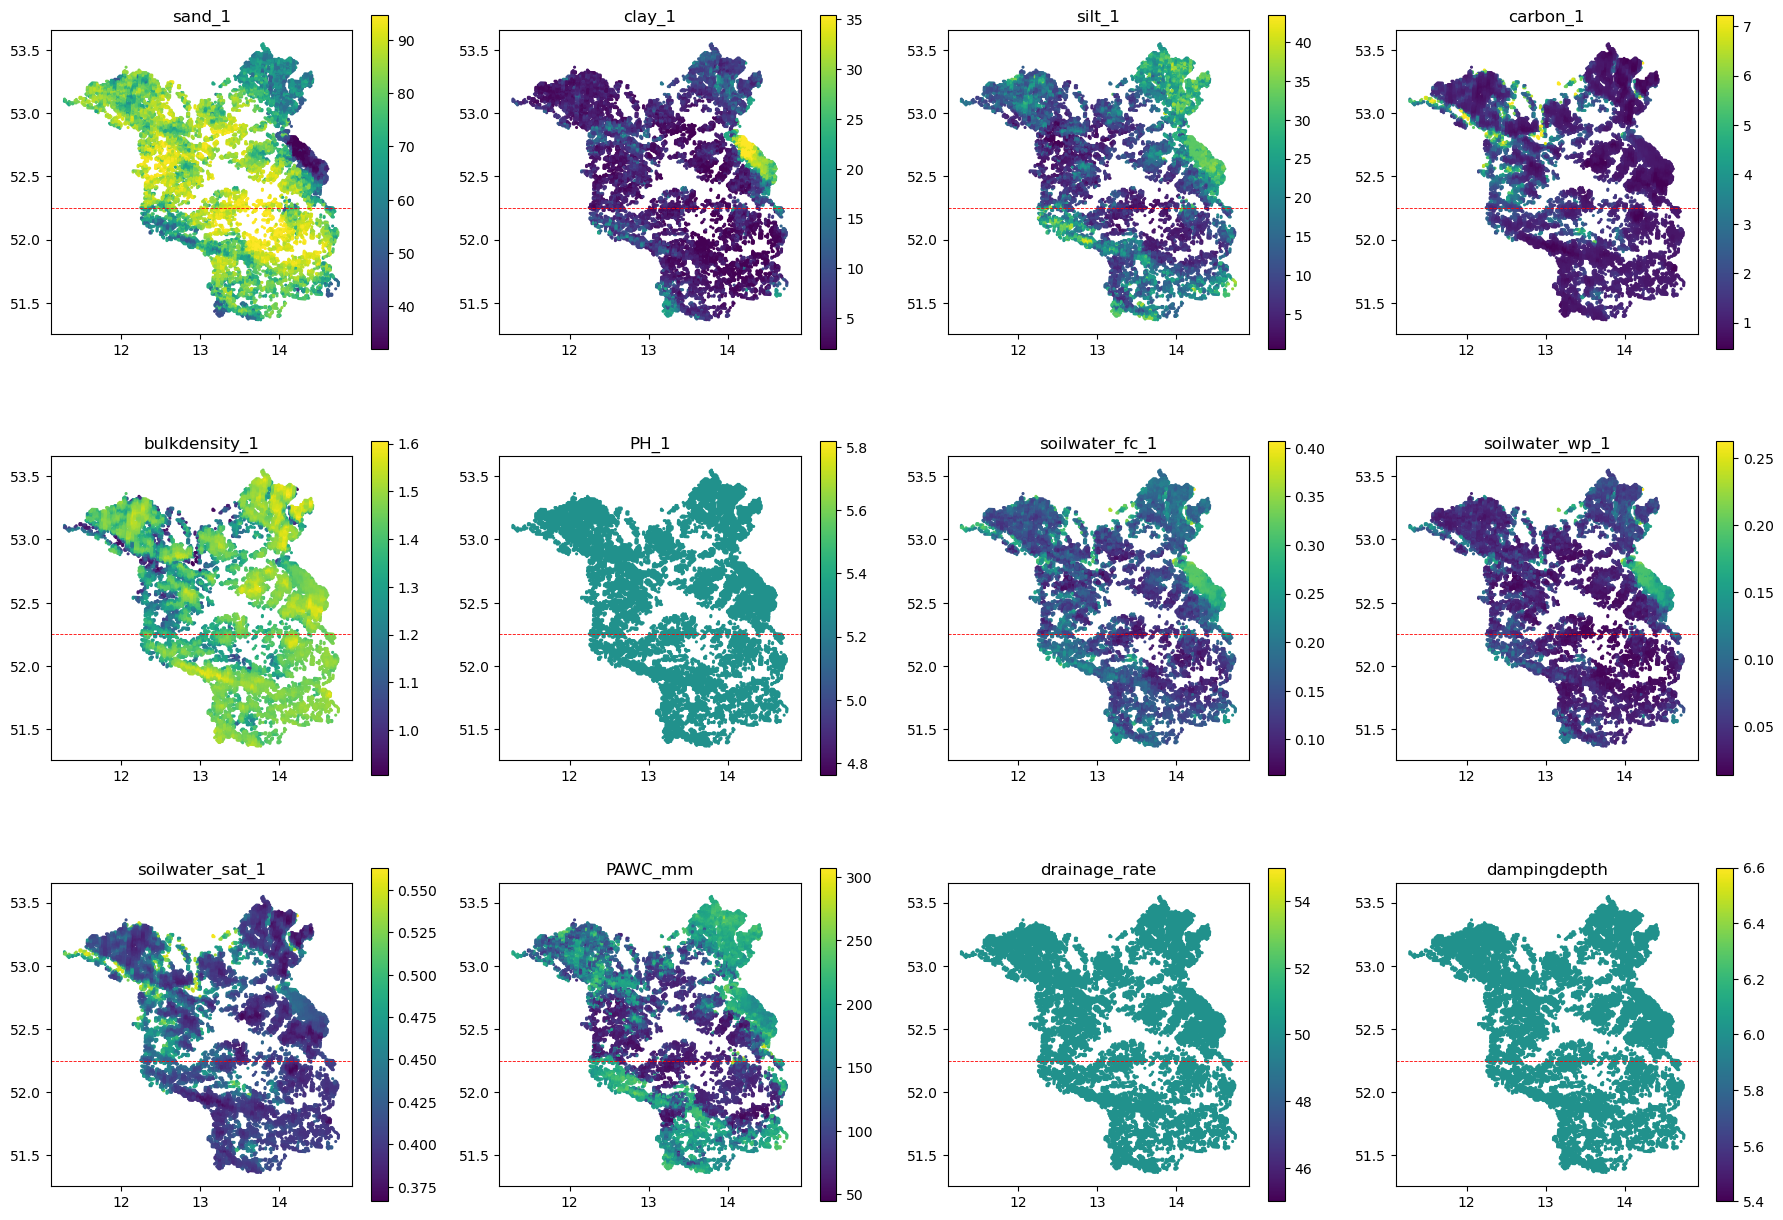

In [7]:
VARS = ['sand_1','clay_1','silt_1','carbon_1','bulkdensity_1','PH_1',
        'soilwater_fc_1','soilwater_wp_1','soilwater_sat_1','PAWC_mm','drainage_rate','dampingdepth']
VARS = [v for v in VARS if v in df]
fig, axs = plt.subplots(3, 4, figsize=(18, 13))
for ax, v in zip(axs.flat, VARS):
    sc = ax.scatter(df.vlon, df.vlat, c=df[v], s=1.5, cmap='viridis')
    ax.axhline(52.25, color='r', lw=.6, ls='--'); ax.set_title(v); ax.set_aspect(1.6)
    plt.colorbar(sc, ax=ax, shrink=.8)
for ax in axs.flat[len(VARS):]: ax.axis('off')
plt.tight_layout()

## 6. Distributions per layer


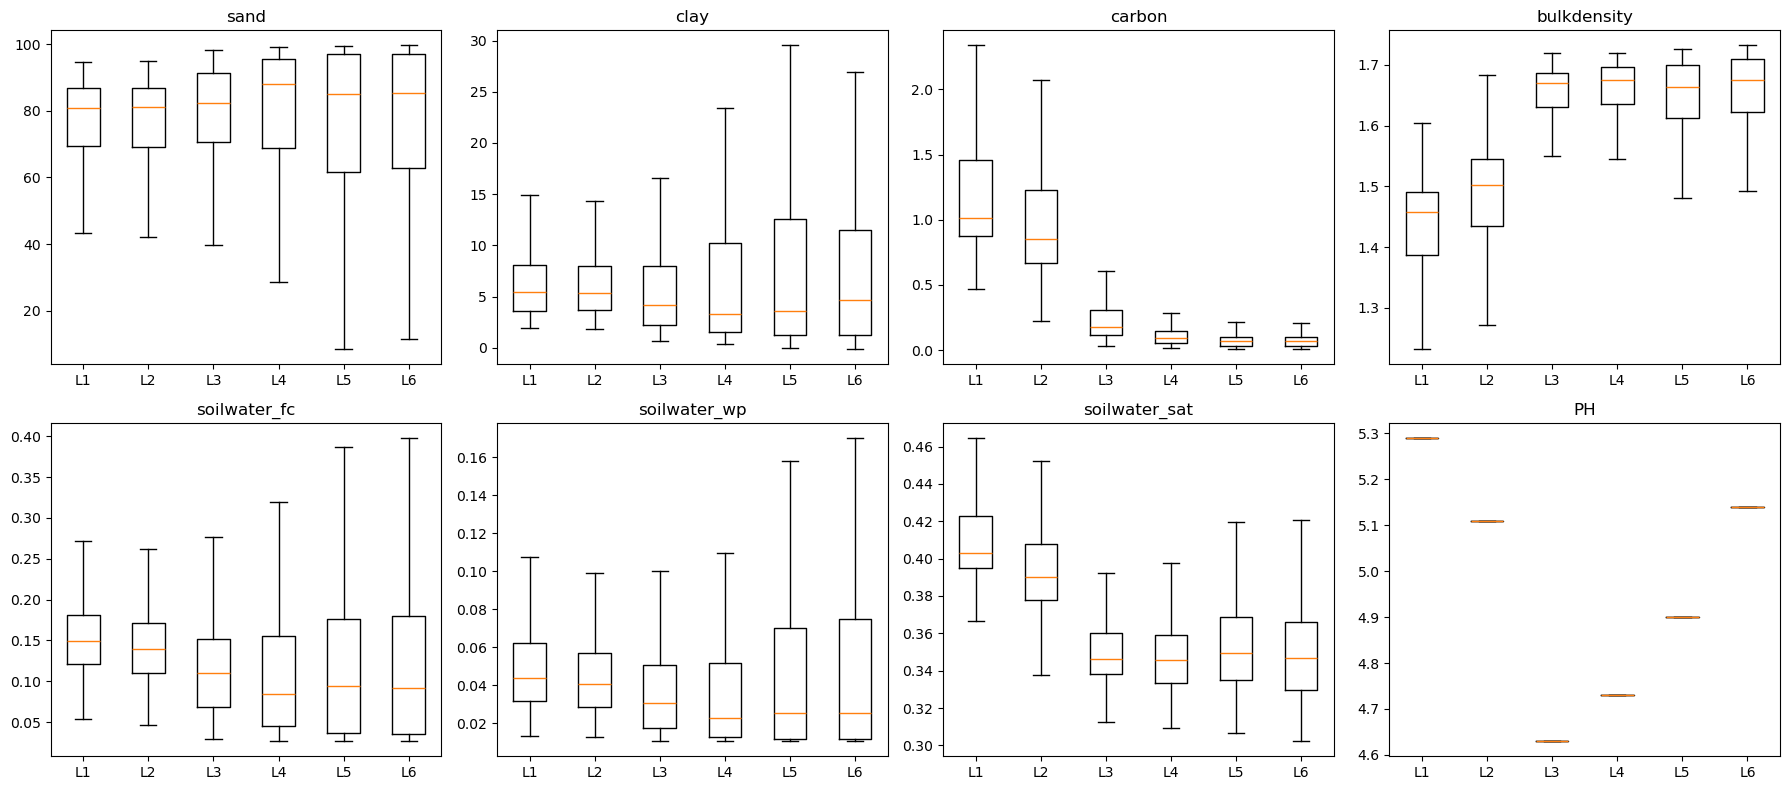

In [16]:
base = ['sand','clay','carbon','bulkdensity','soilwater_fc','soilwater_wp','soilwater_sat','PH']
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for ax, b in zip(axs.flat, base):
    ax.boxplot([df[f'{b}_{i}'] for i in range(1,7)], tick_labels=[f'L{i}' for i in range(1,7)], showfliers=False)
    ax.set_title(b)
plt.tight_layout()

## 7. North vs south of 52.25°N


In [17]:
df['half'] = np.where(df.vlat >= 52.25, 'north', 'south')
df.groupby('half')[['sand_1','clay_1','silt_1','carbon_1','soilwater_fc_1','soilwater_wp_1','PAWC_mm']].median().round(3)

,sand_1,clay_1,silt_1,carbon_1,soilwater_fc_1,soilwater_wp_1,PAWC_mm
half,,,,,,,
north,80.623,5.793,14.242,1.037,0.156,0.047,139.622
south,81.523,4.500,13.465,0.996,0.134,0.037,159.241
